# Fitting orbits to a simulated `epochalypse` system with jaxoplanet and NumPyro

The `epochalypse` catalog is simulated Gaia DR4 epoch astrometry for about five million nearby main-sequence stars, with zero, one or two companions injected around each one. In this tutorial we take a single system out of the catalog and model it the way we would model a real DR4 time series. We build the standard five-parameter astrometric model, add a Keplerian reflex orbit for each companion using `jaxoplanet`, and sample the posterior with NUTS in NumPyro. We fit the same epochs with zero-, one- and two-companion models, compare the three with WAIC, and check the recovered orbits against what was injected.

We will:

1. Load one system's truth and epochs from the catalog. The epochs live on the catalog server, and we read only the rows we need.
2. Solve for the five astrometric parameters by weighted least squares and look at what is left over.
3. Find a starting orbit for each companion with the `kepmodel` periodogram, the same search the catalog's characterization tables were built with. Nothing about the injected orbit is used in the fit; the truth only appears as red lines in the plots at the end.
4. Set up the orbit model and run NUTS for each number of companions.
5. Do all of this for two example systems, one with a single companion and one with two.

The two examples are not hard-coded. They are picked by a rule from the high-SNR injected-solutions tables, so they stay the same kind of system if the catalog is regenerated, and the same cells work for any other system in the catalog if you change the configuration.

First, the imports. The notebook sits in `tutorials/` at the root of the `epochalypse` repository, next to `catalog/` (the server mirror) and `src/epochalypse/` (the package that generated the catalog). We take the mission constants, the design matrix of the five-parameter model, the epoch-table conventions and the periodogram from that package rather than retyping them, so the model we fit here is the model that made the data, and the period search is the one that classified it.

In [1]:
# --- workspace bootstrap ----------------------------------------------------
# This notebook lives in <repo>/tutorials/ next to catalog/ (the server mirror)
# and src/epochalypse/ (the generator package, whose constants, column
# conventions, design matrix and periodogram are imported below).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "catalog" / "data").is_dir() and (p / "src" / "epochalypse").is_dir())
CATALOG = ROOT / "catalog"
CACHE = ROOT / "tutorials" / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
try:
    import epochalypse  # installed (editable) in the locked environment
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
print("repository root:", ROOT)

repository root: /Users/daniel/Desktop/epochalypse_catalog/epochalypse_github


In [2]:
import time
import warnings

import jax
import jax.numpy as jnp
from jax.scipy.special import logsumexp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpyro
import numpyro.distributions as dist
from numpyro.diagnostics import print_summary
from numpyro.distributions import constraints
from numpyro.infer import MCMC, NUTS, Predictive, init_to_value
from numpyro.infer.util import log_likelihood
from jaxoplanet.orbits.keplerian import Central, System

from epochalypse import constants as K
from epochalypse.periodogram.fitting import astrometric_design_matrix, epoch_arrays
from epochalypse.periodogram.periodogram import build_model as kepmodel_five_parameter_model
from epochalypse.periodogram.grid import frequency_segments

jax.config.update("jax_enable_x64", True)   # the catalog was simulated in float64
print("JAX devices:", jax.devices())
print("NumPyro version:", numpyro.__version__)

/Users/daniel/Desktop/epochalypse_catalog/epochalypse_github/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX devices: [CpuDevice(id=0)]
NumPyro version: 0.22.0


## Configuration

Everything you might want to change is in the next cell. `EXAMPLES` names the two systems we fit at the end: each is a population (`n_companions` of 1 or 2), whether to draw from the high-SNR sub-catalog (every companion at SNR$_{\rm tot} \ge 5$), and a rank. The rank is applied after a cut that keeps the fits well behaved. Every injected companion has to be below the deuterium-burning limit, so that these are planets rather than brown dwarfs (the very highest-SNR systems in the catalog are 80 Jupiter-mass companions of M dwarfs, which are not very interesting to fit), and every companion has to complete its orbit within the 5.5 yr DR4 baseline, because an orbit longer than the baseline is degenerate with proper motion and acceleration and a tutorial is not the place for that fight. The survivors are ranked by the SNR of their *weakest* companion, so a two-companion system only ranks highly if both of its companions are well detected.

The chain lengths are short so that the whole notebook runs in a few minutes on a laptop. For anything you intend to publish, make them longer.

In [3]:
# The two worked examples at the end of the notebook. Both are re-derived from
# the high-SNR injected-solutions tables by the rule below, not by index.
EXAMPLES = {
    "one companion":  dict(n_companions=1, high_snr=True, snr_rank=0),
    "two companions": dict(n_companions=2, high_snr=True, snr_rank=0),
}

# Selection rule (see select_system): planetary-mass companions only, every
# orbit completing within the DR4 baseline, ranked by the weakest companion's
# SNR_tot so that a two-companion system has *both* companions well detected.
MAX_PERIOD_YEARS = K.DR4_BASELINE_YEARS   # 5.5 yr
MAX_PLANET_MASS_MJUP = 13.0               # deuterium-burning limit
N_PREVIEW = 8                             # candidates to list

MODEL_ORDERS = (0, 1, 2)

NUM_WARMUP = 500
NUM_SAMPLES = 500
NUM_CHAINS = 2
RNG_SEED = 2026
TARGET_ACCEPT = 0.9

# Priors on the orbit. The period range brackets the catalog's semi-major-axis
# prior (0.03-100 AU); the mass range runs from Mars to the hydrogen-burning limit.
# Omega and M0 are sampled on the real line and wrapped modulo 2pi inside the
# model (a flat circular prior with no 0 / 2pi edge for NUTS to get stuck
# against); Omega is reported folded into [0, pi) because astrometry alone
# cannot tell (omega, Omega) from (omega + pi, Omega + pi).
PERIOD_MIN_YEARS = 0.02
PERIOD_MAX_YEARS = 1000.0
LOG_MASS_MIN = np.log(K.MARS_IN_MJUP)              # log Mjup
LOG_MASS_MAX = np.log(K.MAX_COMPANION_MASS_MJUP)   # 80 Mjup
ECC_MAX = 0.99
TWOPI = 2.0 * np.pi
OMEGA_MAX = np.pi

# Along-scan jitter added in quadrature to the reported per-transit uncertainty.
AL_JITTER_MIN_MAS = 1.0e-3
AL_JITTER_MAX_MAS = 5.0

# Epoch shards: local copy if present, otherwise the catalog server.
SERVER = "https://users.flatironinstitute.org/~apricewhelan/epochalypse"
LOCAL_SHARDS = CATALOG / "data" / "simulated_astrometry"
N_SHARDS = 320
EPOCH_COLUMNS = ["obs_time_tcb", "scan_pos_angle", "parallax_factor_al",
                 "centroid_pos_al", "centroid_pos_error_al"]

## 1. Loading a system

Each population of the catalog comes with two tables. The injected-solutions table (`data/injected_solutions_<population>[_high_snr].parquet`) has one row per system: the star, the injected companions and their detectability SNR. The characterization table (`periodograms/characterization_<population>[_high_snr].parquet`) has the result of the catalog's periodogram search for the same systems and, importantly for us, the `shard` that the system's epochs were written to. The epochs themselves are 28.6 GB of parquet shards that are not part of the mirror in `../catalog/`. A single system is a few hundred rows in one row group of one shard, so we read just that row group off the catalog server with an HTTP range request and cache it under `cache/epochs/`. (If you do have the shards, put them in `../catalog/data/simulated_astrometry/` and they will be used instead.)

From the truth table the fit uses only what a real analysis would have: the stellar mass and radius, which in the catalog come from the star's DR3 properties. The injected orbits are read too, but only for the plots. Two conventions to keep in mind: companion masses are in Jupiter masses and all angles are in degrees. The model below works in solar masses and radians, so `injected_companions` converts, and it also folds $\Omega$ into $[0, \pi)$, the range the fit reports it in. The generator's `epoch_arrays` turns the five epoch columns into the arrays we fit: time in years from the DR4 reference epoch (J2017.5, TCB), the scan angle $\psi$, the along-scan parallax factor, and the along-scan position and its reported uncertainty, both in mas.

In [4]:
def truths_path(n_companions, high_snr):
    return CATALOG / "data" / f"injected_solutions_{n_companions}_companion{'_high_snr' if high_snr else ''}.parquet"


def characterization_path(n_companions, high_snr):
    return CATALOG / "periodograms" / f"characterization_{n_companions}_companion{'_high_snr' if high_snr else ''}.parquet"


def load_truths(n_companions, high_snr=True):
    """The injected-solutions table joined with the periodogram verdict and the shard address."""
    truths = pd.read_parquet(truths_path(n_companions, high_snr))
    chars = pd.read_parquet(characterization_path(n_companions, high_snr), columns=[
        "gaia_source_id", "shard", "shard_row", "n_epochs", "klass", "best_period",
        "width_dex", "detected_cal", "period_reliable_cal",
    ])
    truths["gaia_source_id"] = truths["gaia_source_id"].astype("int64")
    chars["gaia_source_id"] = chars["gaia_source_id"].astype("int64")
    return truths.merge(chars, on="gaia_source_id", how="left")


def companion_cols(frame, stem, n_companions):
    return [f"{stem}_{k}" for k in range(1, n_companions + 1) if f"{stem}_{k}" in frame.columns]


def select_system(n_companions, high_snr=True, snr_rank=0, gaia_source_id=None,
                  max_period=MAX_PERIOD_YEARS, max_mass_mjup=MAX_PLANET_MASS_MJUP, n_preview=N_PREVIEW):
    """One row of the injected-solutions table: by gaia_source_id, or by rank among the
    systems whose companions are all planetary-mass and all orbit within the baseline."""
    truths = load_truths(n_companions, high_snr)
    if gaia_source_id is not None:
        hit = truths.index[truths["gaia_source_id"] == int(gaia_source_id)]
        if hit.empty:
            raise KeyError(f"{gaia_source_id} is not in {truths_path(n_companions, high_snr).name}")
        return truths.loc[hit[0]]
    pmax = truths[companion_cols(truths, "period", n_companions)].max(axis=1)
    mmax = truths[companion_cols(truths, "mass_pl", n_companions)].max(axis=1)
    snr_min = truths[companion_cols(truths, "snr_total", n_companions)].min(axis=1)
    eligible = truths[(pmax < max_period) & (mmax < max_mass_mjup)].assign(snr_weakest=snr_min)
    eligible = eligible.sort_values("snr_weakest", ascending=False).reset_index(drop=True)
    if eligible.empty:
        raise ValueError("no system passes the selection rule")
    show = ["system_id", "n_epochs", "mass_st_msun", "parallax_mas", "snr_weakest", "klass",
            "best_period", "detected_cal"]
    show += [c for k in range(1, n_companions + 1) for c in (f"period_{k}", f"mass_pl_{k}", f"ecc_{k}")]
    print(f"{truths_path(n_companions, high_snr).name}: {len(eligible):,} of {len(truths):,} systems "
          f"have all companions < {max_mass_mjup:g} Mjup and all periods < {max_period:g} yr; "
          f"top {n_preview} by weakest-companion SNR_tot:")
    display(eligible[show].head(n_preview).round(3))
    return eligible.iloc[snr_rank]


def shard_path_or_url(population, shard, n_shards=N_SHARDS):
    name = f"epochs_rank{shard:05d}_of_{n_shards:05d}.parquet"
    local = LOCAL_SHARDS / population / name
    return str(local) if local.exists() else f"{SERVER}/data/simulated_astrometry/{population}/{name}"


def fetch_epochs(population, shard, gaia_source_id, verbose=True):
    """One system's epoch table, sorted by time: from cache/, a local shard, or the server
    (only the row groups holding the system are read, by HTTP range request)."""
    import fsspec
    import pyarrow.parquet as pq

    cache_dir = CACHE / "epochs" / population
    cache_dir.mkdir(parents=True, exist_ok=True)
    cached = cache_dir / f"{int(gaia_source_id)}.parquet"
    if cached.exists():
        return pd.read_parquet(cached)
    target = str(int(gaia_source_id))
    where = shard_path_or_url(population, shard)
    if verbose:
        print(f"fetching epochs of {target} from {where} ...", flush=True)
    opener = open if not where.startswith("http") else fsspec.filesystem("https", block_size=4 * 2**20).open
    with opener(where, "rb") as handle:
        pf = pq.ParquetFile(handle)
        pieces = []
        for group in range(pf.num_row_groups):
            ids = pf.read_row_group(group, columns=["gaia_source_id"]).column(0)
            hit = np.flatnonzero(ids.to_numpy(zero_copy_only=False).astype(str) == target)
            if hit.size:
                pieces.append(pf.read_row_group(group, columns=EPOCH_COLUMNS).to_pandas().iloc[hit])
    if not pieces:
        raise KeyError(f"{target} is not in {where}")
    epochs = pd.concat(pieces).sort_values("obs_time_tcb").reset_index(drop=True)
    epochs.to_parquet(cached, index=False)
    return epochs


def fold_node(omega, Omega):
    """(omega, Omega) and (omega + pi, Omega + pi) are the same astrometric orbit; put Omega in [0, pi)."""
    omega, Omega = omega % TWOPI, Omega % TWOPI
    if Omega >= OMEGA_MAX:
        omega, Omega = (omega + np.pi) % TWOPI, Omega - np.pi
    return omega, Omega


def injected_companions(truth):
    """The injected orbits in the model's vocabulary (years, Msun, radians), inner first.
    The table stores masses in Mjup and angles in degrees. Used only to annotate plots."""
    planets = []
    for k in range(1, int(truth["n_planets"]) + 1):
        omega, Omega = fold_node(np.radians(truth[f"omega_{k}"]), np.radians(truth[f"Omega_{k}"]))
        planets.append({
            "period_years": float(truth[f"period_{k}"]),
            "mass_msun": float(truth[f"mass_pl_{k}"]) * K.MJUP_IN_MSUN,
            "eccentricity": float(truth[f"ecc_{k}"]),
            "cos_i": float(np.cos(np.radians(truth[f"inc_{k}"]))),
            "Omega": float(Omega), "omega": float(omega),
            "M0": float(np.radians(truth[f"M_anom_{k}"])) % TWOPI,
            "alpha_mas": float(truth[f"alpha_mas_{k}"]),
            "snr_total": float(truth[f"snr_total_{k}"]),
        })
    return sorted(planets, key=lambda p: p["period_years"])


def companion_table(planets):
    return pd.DataFrame([{
        "P [yr]": p["period_years"], "Mp [Mjup]": p["mass_msun"] / K.MJUP_IN_MSUN,
        "e": p["eccentricity"], "i [deg]": np.degrees(np.arccos(p["cos_i"])),
        "Omega [deg]": np.degrees(p["Omega"]), "omega [deg]": np.degrees(p["omega"]),
        "M0 [deg]": np.degrees(p["M0"]),
        **({"alpha [mas]": p["alpha_mas"], "SNR_tot": p["snr_total"]} if "alpha_mas" in p else {}),
    } for p in planets], index=range(1, len(planets) + 1)).round(3)


def load_system(truth, verbose=True):
    """Everything one fit needs, from a row of the injected-solutions table."""
    population = f"{int(truth['n_planets'])}_companion"
    epochs = fetch_epochs(population, int(truth["shard"]), int(truth["gaia_source_id"]), verbose)
    t, psi, pfac, y, yerr = epoch_arrays(*[epochs[c].to_numpy(float) for c in EPOCH_COLUMNS])
    system = {
        "system_id": truth["system_id"], "gaia_source_id": int(truth["gaia_source_id"]),
        "truth": truth, "epochs": epochs, "t": t, "psi": psi, "pf": pfac, "y": y, "yerr": yerr,
        "mstar": float(truth["mass_st_msun"]), "rstar": float(truth["radius_st_rsun"]),
        "companions": injected_companions(truth),
    }
    if verbose:
        print(f"\n{system['system_id']}: {len(y)} epochs over {np.ptp(t):.2f} yr; "
              f"M* = {system['mstar']:.3f} Msun, parallax = {truth['parallax_mas']:.2f} mas, "
              f"median reported sigma = {np.median(yerr):.4f} mas")
        print(f"catalog periodogram verdict: klass = {truth['klass']}, best period = "
              f"{truth['best_period']:.3f} yr, detected_cal = {truth['detected_cal']}, "
              f"period_reliable_cal = {truth['period_reliable_cal']}")
        print("\ninjected companions (inner first; for the plots only):")
        display(companion_table(system["companions"]))
    return system

## 2. The five-parameter solution and the orbit model

Before we fit any orbit we solve the linear problem. The along-scan position of a single star is

$$w = \sin\psi\,(\alpha_0 + \mu_\alpha t) + \cos\psi\,(\delta_0 + \mu_\delta t) + \varpi\,f_\varpi ,$$

linear in the five astrometric parameters, so weighted least squares gives them directly. We use this solution twice. Its residuals show us the orbital signal we are about to model, and its values and uncertainties set the centres and widths of the Gaussian priors on the five parameters in the MCMC (widened by a factor of ten and floored, so that adding a companion can still move them).

The reflex motion is computed with `jaxoplanet`. We build a `System` with the star as the central body, add each companion, and sum the central body's displacement in the sky plane. The projection onto the scan direction, $w_{\rm reflex} = -(x\cos\psi + y\sin\psi)$, is the generator's own convention (`epochalypse.astrometry.simulate_along_scan`). Each companion is parameterized by $\log P$, $\log M_p$, $(h, k) = (\sqrt{e}\cos\omega, \sqrt{e}\sin\omega)$, $\cos i$, $\Omega$ and $M_0$, all with uniform priors. The angles $\Omega$ and $M_0$ are sampled on the whole real line with a flat prior and wrapped modulo $2\pi$ inside the model (NumPyro's circular reparameterization), so the posterior is periodic and there is no edge at $0$ or $2\pi$ for the sampler to get stuck against. Astrometry alone cannot distinguish $(\omega, \Omega)$ from $(\omega + \pi, \Omega + \pi)$, so we report $\Omega$ folded into $[0, \pi)$. In the two-companion model the two periods are sorted at every step, so companion 1 is always the inner one and the posterior can be compared with the inner/outer labelling of the truth table.

One more ingredient. The per-epoch uncertainty in the catalog is `sigma_reported`, the formal per-transit error, but the scatter was drawn from the larger `sigma_UEVA`, which includes the calibration floor. This mimics what happens with real Gaia epoch data, and the usual fix is a jitter term added in quadrature, $\sigma_{\rm eff}^2 = \sigma_{\rm reported}^2 + \sigma_{\rm jit}^2$. We fit the jitter with a log-uniform prior, and we will see below that it comes out at a sensible value.

In [5]:
def weighted_linear_solution(t, scan_angle, pf, values, errors):
    X = astrometric_design_matrix(t, scan_angle, pf)
    w = 1.0 / np.square(errors)
    covariance = np.linalg.pinv(X.T @ (w[:, None] * X))
    beta = covariance @ (X.T @ (w * values))
    return beta, covariance, X


BETA_NAMES = ["alpha0_mas", "delta0_mas", "pmra_mas_yr", "pmdec_mas_yr", "parallax_mas"]


def five_parameter_solution(system, show=True):
    """WLS solution, its covariance, and the prior scales derived from it: a few x the
    WLS uncertainty, floored so that a tight fit still leaves the companions room to
    move the linear parameters."""
    beta, cov, X = weighted_linear_solution(system["t"], system["psi"], system["pf"], system["y"], system["yerr"])
    sigma = np.sqrt(np.diag(cov))
    scale = np.maximum(10.0 * sigma, np.array([10.0, 10.0, 10.0, 10.0, 5.0]))
    system.update({"beta_wls": beta, "beta_scale": scale, "X": X})
    if show:
        truth = system["truth"]
        display(pd.DataFrame({"parameter": BETA_NAMES, "WLS": beta, "WLS_sigma": sigma, "prior_scale": scale,
                              "injected": [0.0, 0.0, truth["pmra_mas_yr"], truth["pmdec_mas_yr"], truth["parallax_mas"]]}))
        fig, ax = plt.subplots(figsize=(10, 3.5))
        ax.errorbar(system["t"], system["y"] - X @ beta, yerr=system["yerr"], fmt=".", alpha=0.7)
        ax.axhline(0, color="k", lw=1)
        ax.set(xlabel="time from the DR4 reference epoch [yr]", ylabel="0-companion WLS residual [mas]",
               title=f"{system['system_id']}: residuals of the five-parameter fit")
        plt.show()
    return system


def stellar_reflex_al(t, scan_angle, parallax_mas, planets, mstar, rstar):
    """jaxoplanet stellar reflex projected into Gaia along-scan coordinates
    (the convention of epochalypse.astrometry.simulate_along_scan)."""
    t_days = jnp.asarray(t) * K.DAYS_PER_YEAR
    system = System(Central(mass=jnp.asarray(mstar), radius=jnp.asarray(rstar)))
    for planet in planets:
        period_days = planet["period_years"] * K.DAYS_PER_YEAR
        mean_motion = 2.0 * jnp.pi / period_days
        system = system.add_body(
            period=period_days, mass=planet["mass_msun"],
            eccentricity=planet["eccentricity"], inclination=planet["inclination"],
            omega_peri=planet["omega"], asc_node=planet["Omega"],
            time_peri=-planet["M0"] / mean_motion,
        )
    x_rsun = jnp.zeros_like(t_days)
    y_rsun = jnp.zeros_like(t_days)
    for body in system.bodies:
        x_body, y_body, _ = body.central_position(t_days)
        x_rsun = x_rsun + x_body
        y_rsun = y_rsun + y_body
    x_mas = x_rsun * K.RSUN_IN_AU * parallax_mas
    y_mas = y_rsun * K.RSUN_IN_AU * parallax_mas
    return -(x_mas * jnp.cos(scan_angle) + y_mas * jnp.sin(scan_angle))


def build_astrometric_model(n_planets, beta_loc, beta_scale, mstar, rstar):
    """Along-scan model: WLS-informed Gaussian priors on the five astrometric nuisances,
    per-companion (log P, log Mp, h, k, cos i, Omega, M0) with uniform priors, and an
    along-scan jitter added in quadrature to the reported per-transit uncertainty."""
    log_period_min, log_period_max = np.log(PERIOD_MIN_YEARS), np.log(PERIOD_MAX_YEARS)
    root_e_max = float(np.sqrt(ECC_MAX))
    log_jit_min, log_jit_max = np.log(AL_JITTER_MIN_MAS), np.log(AL_JITTER_MAX_MAS)

    def model(t, scan_angle, pf, reported_error, observed=None):
        alpha0 = numpyro.sample("alpha0_mas", dist.Normal(beta_loc[0], beta_scale[0]))
        delta0 = numpyro.sample("delta0_mas", dist.Normal(beta_loc[1], beta_scale[1]))
        pmra = numpyro.sample("pmra_mas_yr", dist.Normal(beta_loc[2], beta_scale[2]))
        pmdec = numpyro.sample("pmdec_mas_yr", dist.Normal(beta_loc[3], beta_scale[3]))
        parallax = numpyro.sample("parallax_mas", dist.TruncatedNormal(beta_loc[4], beta_scale[4], low=1.0e-3))
        log_al_jitter = numpyro.sample("log_al_jitter_mas", dist.Uniform(log_jit_min, log_jit_max))

        period_logs = [numpyro.sample(f"log_period_{k}", dist.Uniform(log_period_min, log_period_max))
                       for k in range(1, n_planets + 1)]
        if n_planets == 2:   # label inner = 1 / outer = 2 by sorting the periods
            period_logs = list(jnp.sort(jnp.stack(period_logs)))

        planets = []
        for k in range(1, n_planets + 1):
            log_mass = numpyro.sample(f"log_mass_{k}", dist.Uniform(LOG_MASS_MIN, LOG_MASS_MAX))
            h = numpyro.sample(f"h_{k}", dist.Uniform(-root_e_max, root_e_max))
            kk = numpyro.sample(f"k_{k}", dist.Uniform(-root_e_max, root_e_max))
            eccentricity = h**2 + kk**2
            numpyro.factor(f"ecc_bound_{k}", jnp.where(eccentricity < ECC_MAX, 0.0, -jnp.inf))
            cos_i = numpyro.sample(f"cos_i_{k}", dist.Uniform(-1.0, 1.0))
            # circular reparameterization: a flat prior on the real line, wrapped mod 2pi
            Omega = numpyro.sample(f"Omega_{k}_unwrapped", dist.ImproperUniform(constraints.real, (), ())) % TWOPI
            M0 = numpyro.sample(f"M0_{k}_unwrapped", dist.ImproperUniform(constraints.real, (), ())) % TWOPI
            omega = jnp.arctan2(kk, h)
            period_years = jnp.exp(period_logs[k - 1])
            mass_mjup = jnp.exp(log_mass)
            numpyro.deterministic(f"period_years_{k}", period_years)
            numpyro.deterministic(f"mass_mjup_{k}", mass_mjup)
            numpyro.deterministic(f"eccentricity_{k}", eccentricity)
            # report (omega, Omega) with Omega folded into [0, pi); it is the same orbit
            flip = Omega >= OMEGA_MAX
            numpyro.deterministic(f"Omega_{k}", jnp.where(flip, Omega - jnp.pi, Omega))
            numpyro.deterministic(f"omega_{k}", jnp.where(flip, omega + jnp.pi, omega) % TWOPI)
            numpyro.deterministic(f"M0_{k}", M0)
            planets.append({
                "period_years": period_years, "mass_msun": mass_mjup * K.MJUP_IN_MSUN,
                "eccentricity": eccentricity, "inclination": jnp.arccos(cos_i),
                "omega": omega, "Omega": Omega, "M0": M0,
            })

        sin_psi, cos_psi = jnp.sin(scan_angle), jnp.cos(scan_angle)
        astrometry = sin_psi * (alpha0 + pmra * t) + cos_psi * (delta0 + pmdec * t) + parallax * pf
        reflex = stellar_reflex_al(t, scan_angle, parallax, planets, mstar, rstar) if n_planets else 0.0
        mu = numpyro.deterministic("mu", astrometry + reflex)
        sigma = jnp.sqrt(reported_error**2 + jnp.exp(log_al_jitter)**2)
        numpyro.sample("obs", dist.Normal(mu, sigma), obs=observed)

    return model

## 3. A starting point from the periodogram

NUTS needs somewhere to start, and for an orbit the period is the hard part: the likelihood is a forest of narrow peaks in period, and a chain started at the wrong one will happily stay there. We do what one would do with real data and run a periodogram first. The catalog's characterization tables were built with the `kepmodel` astrometric periodogram ([Delisle et al. 2016](https://ui.adsabs.harvard.edu/abs/2016A%26A...590A.134D)), on a trial grid that the generator package defines, so we use exactly that: build `kepmodel`'s five-parameter model of the epochs, scan the grid for the period that most reduces $\chi^2$, and add a Keplerian there. `kepmodel` guesses the remaining orbital elements from the data at that period, fits them, and then we can run the periodogram again on the residuals to look for a second companion. Each pass gives us the starting orbit for one more companion, so a single iterative search provides the start for both the one- and the two-companion models.

`kepmodel` parameterizes the orbit by its Thiele-Innes constants, but it can hand them back as Campbell elements, and the conversion to our parameterization is short. The angular semi-major axis $a_0$ of the star's orbit gives the companion mass through Kepler's law, $a_0 = \varpi\, a\, M_p / (M_\star + M_p)$ with $a^3 = (M_\star + M_p) P^2$, which we solve by iteration using the least-squares parallax. The one subtlety is $\omega$: `kepmodel` describes the orbit of the star, while `jaxoplanet` is parameterized by the companion's, and the two differ by $180^\circ$ in the argument of pericentre. With that shift the two models give the same $\chi^2$ to all digits, which the search prints as a check.

In [6]:
SEGMENTS = frequency_segments()     # the catalog's trial grid (rad / yr)
CAMPBELL = ["P", "M0", "e", "as", "i", "w", "bigw"]
THIELE_INNES = ["P", "M0", "e", "TIA", "TIB", "TIF", "TIG"]


def residual_periodogram(model):
    """Delta chi^2 of a circular orbit at every trial period, against the model as it
    stands (five parameters plus any Keplerians already fitted). kepmodel's own grid."""
    u = model.cov.solveL(model.residuals()) / model.cov.sqD()
    chi2_base = float(u @ u)
    nus, zs = [], []
    for nu0, dnu, nfreq in SEGMENTS:
        nu, z = model.periodogram(nu0, dnu, nfreq)
        nus.append(nu)
        zs.append(z)
    nu, z = np.concatenate(nus), np.concatenate(zs)
    order = np.argsort(nu)
    nu, z = nu[order], z[order]
    keep = np.concatenate([[True], np.diff(nu) > 0])
    return (TWOPI / nu[keep])[::-1], (z[keep] * chi2_base)[::-1], chi2_base


def mass_from_photocentre_orbit(a0_mas, period_years, parallax_mas, mstar):
    """Companion mass [Msun] from the star's angular semi-major axis, by iterating
    a0 = parallax * a * Mp / (M* + Mp) with a^3 = (M* + Mp) P^2."""
    mp = 0.0
    for _ in range(50):
        mp = a0_mas / parallax_mas * (mstar + mp) ** (2.0 / 3.0) / period_years ** (2.0 / 3.0)
    return float(mp)


def campbell_to_model(kep, parallax_mas, mstar):
    """One kepmodel Keplerian -> the orbit in our vocabulary (companion's orbit, Omega in [0, pi))."""
    kep.set_param(CAMPBELL)
    P, M0, e, a0, inc, w, W = (float(v) for v in kep.get_value())
    kep.set_param(THIELE_INNES)
    omega, Omega = fold_node(w + np.pi, W)   # star's orbit -> companion's orbit
    return {"period_years": P, "mass_msun": mass_from_photocentre_orbit(a0, P, parallax_mas, mstar),
            "eccentricity": float(np.clip(e, 1e-4, ECC_MAX - 1e-3)), "cos_i": float(np.cos(inc)),
            "Omega": Omega, "omega": omega, "M0": M0 % TWOPI}


def chi2_at(system, planets):
    """chi^2 of our model at a set of orbits, with the five linear parameters re-solved."""
    reflex = np.asarray(stellar_reflex_al(system["t"], system["psi"], system["beta_wls"][4], [
        {**p, "inclination": np.arccos(p["cos_i"])} for p in planets], system["mstar"], system["rstar"]))
    beta, _, X = weighted_linear_solution(system["t"], system["psi"], system["pf"], system["y"] - reflex, system["yerr"])
    return float(np.sum(((system["y"] - reflex - X @ beta) / system["yerr"]) ** 2))


def periodogram_search(system, max_order=max(MODEL_ORDERS), show=True):
    """Iterate periodogram -> add a Keplerian at the peak -> refit, up to max_order companions.
    Stores system['starts'][n] = the n orbits to start the n-companion model from."""
    model = kepmodel_five_parameter_model(system["t"], system["psi"], system["pf"], system["y"], system["yerr"])
    parallax = float(system["beta_wls"][4])
    starts, curves = {0: []}, []
    for n in range(1, max_order + 1):
        periods, power, chi2_before = residual_periodogram(model)
        best = float(periods[np.argmax(power)])
        curves.append((n, periods, power, best))
        model.add_keplerian_from_period(best)
        model.fit()
        planets = [campbell_to_model(model.keplerian[name], parallax, system["mstar"]) for name in model.keplerian]
        starts[n] = sorted(planets, key=lambda p: p["period_years"])
        print(f"companion {n}: periodogram peak at P = {best:.4f} yr (delta chi2 = {power.max():.1f}); "
              f"after the kepmodel fit chi2 = {float(model.chi2()):.1f}, our model at the converted orbits: "
              f"{chi2_at(system, starts[n]):.1f}")
    system["starts"] = starts
    if show:
        fig, axes = plt.subplots(len(curves), 1, figsize=(10, 2.6 * len(curves)), sharex=True, squeeze=False)
        for ax, (n, periods, power, best) in zip(axes[:, 0], curves):
            ax.plot(periods, power, lw=0.8, color="k")
            ax.axvline(best, color="C3", lw=1.2, label=f"peak: {best:.3f} yr")
            for p in system["companions"]:
                ax.axvline(p["period_years"], color="C0", ls="--", lw=1, alpha=0.7,
                           label="injected" if p is system["companions"][0] else None)
            ax.set(xscale="log", ylabel=rf"$\Delta\chi^2$, {n - 1} fitted")
            ax.legend(loc="upper right", fontsize=8)
        axes[-1, 0].set_xlabel("trial period [yr]")
        axes[0, 0].set_title(f"{system['system_id']}: kepmodel periodograms, one companion added per pass")
        plt.tight_layout()
        plt.show()
        print("starting orbits for the highest-order model (converted from the kepmodel fit):")
        display(companion_table(starts[max_order]))
    return starts

## 4. Sampling and model comparison

We sample each model with NUTS, two chains and a dense mass matrix. The astrometric parameters start at the least-squares solution and the companions at the orbits the periodogram search found for that model order. The injected orbit is never used; it only draws the red lines in the plots.

To compare the three models we compute WAIC from the pointwise log-likelihood of the posterior samples. WAIC is not a Bayesian evidence and we do not pretend it is. It is a cheap, sample-based criterion that penalizes the extra parameters, and it is enough to tell a decisive detection from an overfit. We also plot the residuals of each model and, for the model with the injected number of companions, a corner plot of each companion's orbit against the truth.

In [7]:
def make_initial_values(system, n_planets):
    beta = system["beta_wls"]
    values = {
        "alpha0_mas": float(beta[0]), "delta0_mas": float(beta[1]), "pmra_mas_yr": float(beta[2]),
        "pmdec_mas_yr": float(beta[3]), "parallax_mas": float(beta[4]),
        "log_al_jitter_mas": float(np.log(np.sqrt(AL_JITTER_MIN_MAS * AL_JITTER_MAX_MAS))),
    }
    lp_min, lp_max = np.log(PERIOD_MIN_YEARS), np.log(PERIOD_MAX_YEARS)
    root_e_max = float(np.sqrt(ECC_MAX))
    for k, planet in enumerate(system["starts"][n_planets], start=1):
        e = float(np.clip(planet["eccentricity"], 1e-4, ECC_MAX - 1e-3))
        omega = float(planet["omega"]) % TWOPI
        values[f"log_period_{k}"] = float(np.clip(np.log(planet["period_years"]), lp_min + 1e-4, lp_max - 1e-4))
        values[f"log_mass_{k}"] = float(np.clip(np.log(planet["mass_msun"] / K.MJUP_IN_MSUN), LOG_MASS_MIN + 1e-4, LOG_MASS_MAX - 1e-4))
        values[f"h_{k}"] = float(np.clip(np.sqrt(e) * np.cos(omega), -root_e_max + 1e-4, root_e_max - 1e-4))
        values[f"k_{k}"] = float(np.clip(np.sqrt(e) * np.sin(omega), -root_e_max + 1e-4, root_e_max - 1e-4))
        values[f"cos_i_{k}"] = float(np.clip(planet["cos_i"], -0.9999, 0.9999))
        values[f"Omega_{k}_unwrapped"] = float(planet["Omega"] % TWOPI)
        values[f"M0_{k}_unwrapped"] = float(planet["M0"] % TWOPI)
    return values


def data_args(system):
    return (jnp.asarray(system["t"]), jnp.asarray(system["psi"]), jnp.asarray(system["pf"]), jnp.asarray(system["yerr"]))


def fit_model(system, n_planets, rng_key, num_warmup=NUM_WARMUP, num_samples=NUM_SAMPLES):
    model = build_astrometric_model(n_planets, system["beta_wls"], system["beta_scale"], system["mstar"], system["rstar"])
    kernel = NUTS(model, init_strategy=init_to_value(values=make_initial_values(system, n_planets)),
                  target_accept_prob=TARGET_ACCEPT, dense_mass=True)
    sampler = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=NUM_CHAINS,
                   chain_method="sequential", progress_bar=False)
    sampler.run(rng_key, *data_args(system), observed=jnp.asarray(system["y"]), extra_fields=("potential_energy",))
    return {"model": model, "sampler": sampler, "samples": sampler.get_samples()}


def print_fit_summary(fit):
    """NUTS summary of the physical parameters (the wrapped angles rather than the
    unwrapped sites, and not the 'mu' prediction at every epoch)."""
    chains = fit["sampler"].get_samples(group_by_chain=True)
    print_summary({k: v for k, v in chains.items() if k != "mu" and not k.endswith("_unwrapped")}, prob=0.9)


def run_fits(system, orders=MODEL_ORDERS, seed=RNG_SEED):
    """Fit every model order to the same data; prints the NUTS summary of each."""
    fits = {}
    keys = jax.random.split(jax.random.key(seed), len(orders))
    for order, key in zip(orders, keys):
        print("\n" + "=" * 78)
        print(f"{order}-companion model for {system['system_id']}")
        print("=" * 78)
        start = time.time()
        fits[order] = fit_model(system, order, key)
        print(f"({time.time() - start:.0f} s incl. compilation)")
        print_fit_summary(fits[order])
    system["fits"] = fits
    return fits


def compute_waic(system, fit):
    ll = np.asarray(log_likelihood(fit["model"], fit["samples"], *data_args(system),
                                   observed=jnp.asarray(system["y"]))["obs"])
    lppd = np.sum(logsumexp(jnp.asarray(ll), axis=0) - np.log(ll.shape[0]))
    p_waic = np.sum(np.var(ll, axis=0, ddof=1))
    return float(-2.0 * (lppd - p_waic)), float(p_waic)


def compare_models(system):
    """WAIC table and the residual panels of the fitted orders."""
    fits = system["fits"]
    rows = []
    for order, fit in fits.items():
        waic, p_waic = compute_waic(system, fit)
        divergent = int(np.asarray(fit["sampler"].get_extra_fields()["diverging"]).sum())
        jitter = np.exp(np.asarray(fit["samples"]["log_al_jitter_mas"]))
        rows.append({"n_companions": order, "WAIC": waic, "p_WAIC": p_waic, "divergences": divergent,
                     "jitter_mas (median)": float(np.median(jitter))})
    comparison = pd.DataFrame(rows).sort_values("WAIC")
    comparison["delta_WAIC"] = comparison["WAIC"] - comparison["WAIC"].min()
    print(f"{system['system_id']}: {int(system['truth']['n_planets'])} companion(s) injected")
    display(comparison.reset_index(drop=True))

    fig, axes = plt.subplots(len(fits), 1, figsize=(11, 2.8 * len(fits)), sharex=True)
    for ax, (order, fit) in zip(np.atleast_1d(axes), fits.items()):
        predictive = Predictive(fit["model"], posterior_samples=fit["samples"], return_sites=["mu"])
        mu = np.asarray(predictive(jax.random.key(100 + order), *data_args(system), observed=None)["mu"])
        median = np.median(mu, axis=0)
        lo, hi = np.percentile(mu, [16, 84], axis=0)
        ax.errorbar(system["t"], system["y"] - median, yerr=system["yerr"], fmt=".", alpha=0.6)
        ax.fill_between(system["t"], system["y"] - hi, system["y"] - lo, alpha=0.2)
        ax.axhline(0, color="k", lw=1)
        ax.set_ylabel(f"{order}-companion residual [mas]")
    np.atleast_1d(axes)[0].set_title(f"{system['system_id']}: data minus posterior-median model")
    np.atleast_1d(axes)[-1].set_xlabel("time from the DR4 reference epoch [yr]")
    plt.tight_layout()
    plt.show()
    return comparison


CORNER_LABELS = [r"$P$ [yr]", r"$M_p$ [$M_{\rm Jup}$]", r"$e$", r"$i$ [deg]",
                 r"$\Omega$ [deg]", r"$\omega$ [deg]", r"$M_0$ [deg]"]


def node_centre(samples, k):
    """Centre of the display range for Omega_k: the circular mean of 2 Omega (period pi)."""
    Omega = np.asarray(samples[f"Omega_{k}"])
    return 0.5 * np.arctan2(np.mean(np.sin(2 * Omega)), np.mean(np.cos(2 * Omega))) % np.pi


def fold_to_centre(omega, Omega, centre):
    """Shift (omega, Omega) by the (pi, pi) degeneracy so Omega lies within pi/2 of centre.
    For the plots only: a posterior straddling Omega = 0 or pi would otherwise look bimodal."""
    shift = np.round((Omega - centre) / np.pi) * np.pi
    return (omega - shift) % TWOPI, Omega - shift


def posterior_matrix(samples, k, centre):
    omega, Omega = fold_to_centre(np.asarray(samples[f"omega_{k}"]), np.asarray(samples[f"Omega_{k}"]), centre)
    return np.column_stack([
        np.asarray(samples[f"period_years_{k}"]), np.asarray(samples[f"mass_mjup_{k}"]),
        np.asarray(samples[f"eccentricity_{k}"]),
        np.degrees(np.arccos(np.clip(np.asarray(samples[f"cos_i_{k}"]), -1.0, 1.0))),
        np.degrees(Omega), np.degrees(omega), np.degrees(np.asarray(samples[f"M0_{k}"])),
    ])


def truth_vector(p, centre):
    omega, Omega = fold_to_centre(p["omega"], p["Omega"], centre)
    return [p["period_years"], p["mass_msun"] / K.MJUP_IN_MSUN, p["eccentricity"],
            np.degrees(np.arccos(np.clip(p["cos_i"], -1.0, 1.0))),
            np.degrees(Omega), np.degrees(omega), np.degrees(p["M0"])]


def recovery_table(system, order=None):
    """Posterior median and 16-84% interval of each companion's P, Mp and e against the injected
    values, from the fit whose order matches the injected system (or ``order``)."""
    order = int(system["truth"]["n_planets"]) if order is None else order
    samples = system["fits"][order]["samples"]
    rows = []
    for k, p in enumerate(system["companions"][:order], start=1):
        for name, col, true in (("P [yr]", f"period_years_{k}", p["period_years"]),
                                ("Mp [Mjup]", f"mass_mjup_{k}", p["mass_msun"] / K.MJUP_IN_MSUN),
                                ("e", f"eccentricity_{k}", p["eccentricity"])):
            lo, med, hi = np.percentile(np.asarray(samples[col]), [16, 50, 84])
            rows.append({"companion": k, "parameter": name, "injected": true, "median": med,
                         "-1sigma": med - lo, "+1sigma": hi - med, "pull": (med - true) / (0.5 * (hi - lo))})
    return pd.DataFrame(rows).round(4)


def corner_plots(system, order=None):
    """Corner plot of each companion's recovered orbit (fit of the injected order) vs the truth (red)."""
    import corner

    order = int(system["truth"]["n_planets"]) if order is None else order
    samples = system["fits"][order]["samples"]
    for k, p in enumerate(system["companions"][:order], start=1):
        centre = node_centre(samples, k)
        fig = corner.corner(posterior_matrix(samples, k, centre), labels=CORNER_LABELS, truths=truth_vector(p, centre),
                            truth_color="C3", quantiles=[0.16, 0.5, 0.84], show_titles=True,
                            title_fmt=".3g", title_kwargs={"fontsize": 9})
        fig.suptitle(f"{system['system_id']}  -  companion {k}/{order} ({order}-companion fit);  red = injected truth",
                     y=1.02, fontsize=12)
        plt.show()

## 5. Example 1: one companion

The first example is the planetary-mass single-companion system with the highest SNR in the high-SNR sub-catalog, after the cuts above. `select_system` prints the top of the ranking so you can see the neighbours, and `load_system` fetches the epochs and prints the catalog's own verdict on the system (the periodogram class, the best period and the calibrated detection flag) next to the injected orbit.

injected_solutions_1_companion_high_snr.parquet: 66,247 of 436,883 systems have all companions < 13 Mjup and all periods < 5.5 yr; top 8 by weakest-companion SNR_tot:


,system_id,n_epochs,mass_st_msun,parallax_mas,snr_weakest,klass,best_period,detected_cal,period_1,mass_pl_1,ecc_1
0,1_companion_2928420272788743424,133,0.194,50.398,492.530,unimodal,3.057,True,2.971,7.727,0.711
1,1_companion_6224387727748521344,123,0.090,141.789,435.239,unimodal,1.063,True,1.065,9.427,0.499
2,1_companion_2439763461052925824,66,0.190,47.711,435.038,unimodal,4.280,True,4.601,11.342,0.567
3,1_companion_3046640175314154624,69,0.172,58.494,414.031,unimodal,3.941,True,4.205,8.364,0.482
4,1_companion_1961385914819977216,119,0.198,45.595,375.560,unimodal,1.220,True,1.220,10.309,0.403
5,1_companion_2604921308819786624,69,0.193,46.241,351.032,unimodal,2.014,True,2.087,9.406,0.787
6,1_companion_5970971561918864768,64,0.557,67.233,348.931,unimodal,4.958,True,4.554,12.937,0.406
7,1_companion_1466009540856759680,109,0.144,70.896,334.741,unimodal,4.890,True,5.106,5.764,0.720



1_companion_2928420272788743424: 133 epochs over 5.19 yr; M* = 0.194 Msun, parallax = 50.40 mas, median reported sigma = 0.0345 mas
catalog periodogram verdict: klass = unimodal, best period = 3.057 yr, detected_cal = True, period_reliable_cal = True

injected companions (inner first; for the plots only):


,P [yr],Mp [Mjup],e,i [deg],Omega [deg],omega [deg],M0 [deg],alpha [mas],SNR_tot
1,2.971,7.727,0.711,94.724,55.753,81.246,311.939,2.239,492.53


,parameter,WLS,WLS_sigma,prior_scale,injected
0,alpha0_mas,0.416336,0.004187,10.0,0.000000
1,delta0_mas,0.466291,0.005005,10.0,0.000000
2,pmra_mas_yr,-124.942083,0.002977,10.0,-124.803375
3,pmdec_mas_yr,-67.911131,0.003285,10.0,-67.882092
4,parallax_mas,50.282589,0.007504,5.0,50.398379


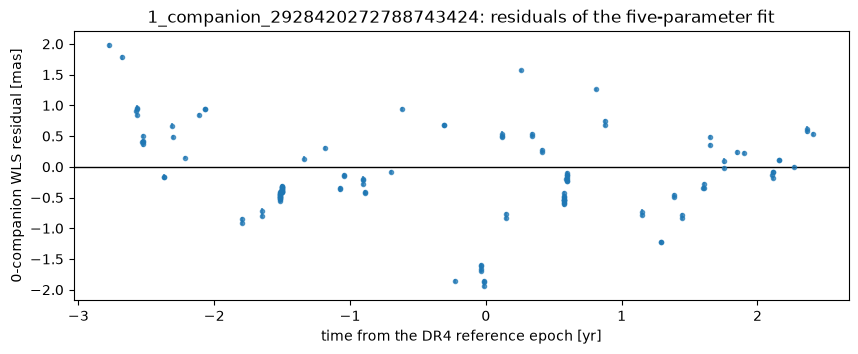

In [8]:
cfg = EXAMPLES["one companion"]
truth_1 = select_system(cfg["n_companions"], cfg["high_snr"], cfg["snr_rank"])
system_1 = load_system(truth_1)
system_1 = five_parameter_solution(system_1)

The star is an M dwarf at 20 pc and the companion is a 7.7 Jupiter-mass planet on a very eccentric ($e = 0.71$) 3 yr orbit. Its reflex semi-major axis of 2.2 mas is enormous next to the 0.035 mas per-epoch uncertainty, which is what an SNR of about 500 means. The least-squares residuals show the orbit plainly: a few tenths of a mas, clearly structured in time, and far larger than the error bars. The catalog's periodogram found it too, at 3.06 yr against the injected 2.97.

companion 1: periodogram peak at P = 3.0570 yr (delta chi2 = 54031.3); after the kepmodel fit chi2 = 194.0, our model at the converted orbits: 194.0


companion 2: periodogram peak at P = 0.0029 yr (delta chi2 = 32.2); after the kepmodel fit chi2 = 152.9, our model at the converted orbits: 152.9


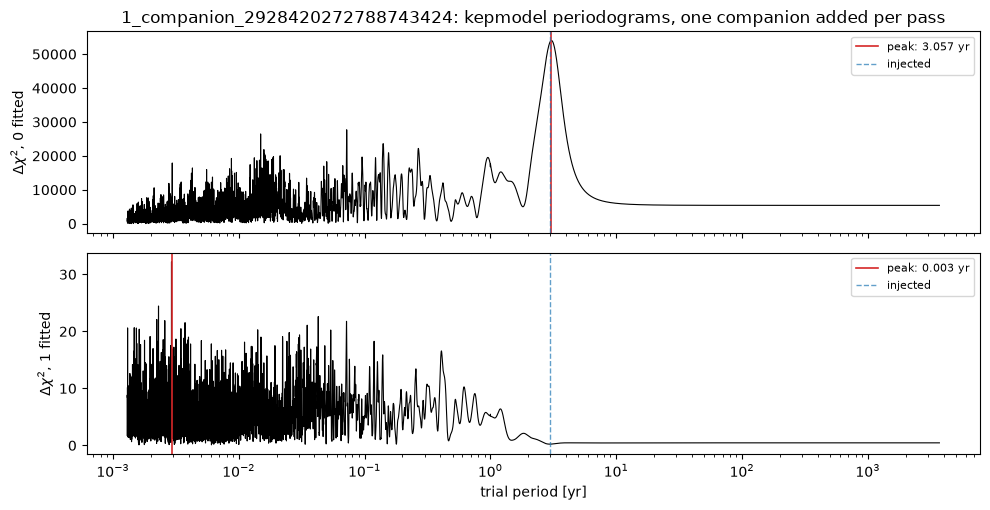

starting orbits for the highest-order model (converted from the kepmodel fit):


,P [yr],Mp [Mjup],e,i [deg],Omega [deg],omega [deg],M0 [deg]
1,0.003,45.132,0.950,79.35,124.838,84.642,339.707
2,2.969,7.659,0.701,94.16,56.264,83.077,310.772


In [9]:
starts_1 = periodogram_search(system_1)

The periodogram has one peak that dwarfs everything else, a $\Delta\chi^2$ of 54,000 at 3.06 yr. The kepmodel fit at that period lands at $P = 2.969$ yr, $e = 0.70$ and 7.66 Jupiter masses, all within a percent or two of the injected orbit before any MCMC has run. (The periodogram peak itself is 3% off, because the periodogram assumes a circular orbit; the Keplerian fit lets the period float and includes the eccentricity, and that corrects it.) The $\chi^2$ check at the end of each line confirms the conversion: our `jaxoplanet` model evaluated at the converted orbit gives exactly the $\chi^2$ kepmodel reported.

The second pass is the honest result of searching residuals that contain nothing. The highest peak is a $\Delta\chi^2$ of 32 at a period of one day, right at the edge of the grid, against 54,000 for the real companion, and kepmodel dutifully fits a 45 Jupiter-mass, $e = 0.95$ companion to it. That is the start the two-companion model gets, and we will see what it makes of it.

In [10]:
fits_1 = run_fits(system_1)


0-companion model for 1_companion_2928420272788743424


(4 s incl. compilation)

                         mean       std    median      5.0%     95.0%     n_eff     r_hat
         alpha0_mas      0.42      0.09      0.42      0.28      0.56    915.48      1.00
         delta0_mas      0.45      0.11      0.45      0.29      0.65    920.83      1.00
  log_al_jitter_mas     -0.30      0.06     -0.31     -0.41     -0.21    917.52      1.00
       parallax_mas     50.34      0.16     50.34     50.07     50.60   1337.87      1.00
       pmdec_mas_yr    -67.89      0.07    -67.89    -68.01    -67.78    983.67      1.00
        pmra_mas_yr   -124.94      0.06   -124.94   -125.04   -124.85   1219.58      1.00


1-companion model for 1_companion_2928420272788743424


(11 s incl. compilation)

                         mean       std    median      5.0%     95.0%     n_eff     r_hat
               M0_1      5.43      0.01      5.43      5.42      5.45    648.61      1.00
            Omega_1      0.98      0.01      0.98      0.97      0.99    773.44      1.00
         alpha0_mas      0.03      0.02      0.03      0.01      0.07    529.44      1.00
            cos_i_1     -0.07      0.00     -0.07     -0.08     -0.07    473.51      1.00
         delta0_mas      0.06      0.02      0.06      0.03      0.09    455.65      1.00
     eccentricity_1      0.70      0.01      0.70      0.69      0.72    416.76      1.01
                h_1      0.11      0.01      0.11      0.10      0.12    498.55      1.00
                k_1      0.83      0.01      0.83      0.82      0.84    422.03      1.01
  log_al_jitter_mas     -3.71      0.22     -3.69     -4.05     -3.34    431.06      1.00
         log_mass_1      2.04      0.02      2.04      2.01      2.07    4

(26 s incl. compilation)

                         mean       std    median      5.0%     95.0%     n_eff     r_hat
               M0_1      3.30      1.54      3.34      0.93      6.15     25.82      1.11
               M0_2      5.43      0.01      5.43      5.42      5.45    185.06      1.01
            Omega_1      1.56      1.01      1.60      0.18      2.99     33.39      1.01
            Omega_2      0.98      0.01      0.98      0.97      0.99     35.18      1.04
         alpha0_mas      0.03      0.02      0.03     -0.00      0.06     92.28      1.00
            cos_i_1      0.04      0.46      0.07     -0.61      0.82      9.22      1.24
            cos_i_2     -0.07      0.00     -0.07     -0.08     -0.07     66.96      1.03
         delta0_mas      0.07      0.03      0.06      0.02      0.10      7.52      1.12
     eccentricity_1      0.55      0.30      0.59      0.13      0.99      2.88      1.35
     eccentricity_2      0.70      0.01      0.70      0.69      0.72     

The one-companion fit converges cleanly: $\hat R \approx 1$, hundreds of effective samples per parameter, no divergences. The two-companion fit does not. Its second companion started on a noise peak and has nothing to fit, so it wanders through the prior, and the sampler reports hundreds of divergences and $\hat R$ well above one for the parameters it drags along. That is what an unneeded companion looks like, and it is worth learning to recognize.

1_companion_2928420272788743424: 1 companion(s) injected


,n_companions,WAIC,p_WAIC,divergences,jitter_mas (median),delta_WAIC
0,1,-435.310621,13.860249,0,0.024899,0.000000
1,2,-431.393383,15.986289,639,0.023995,3.917238
2,0,302.897446,6.307622,0,0.736530,738.208068


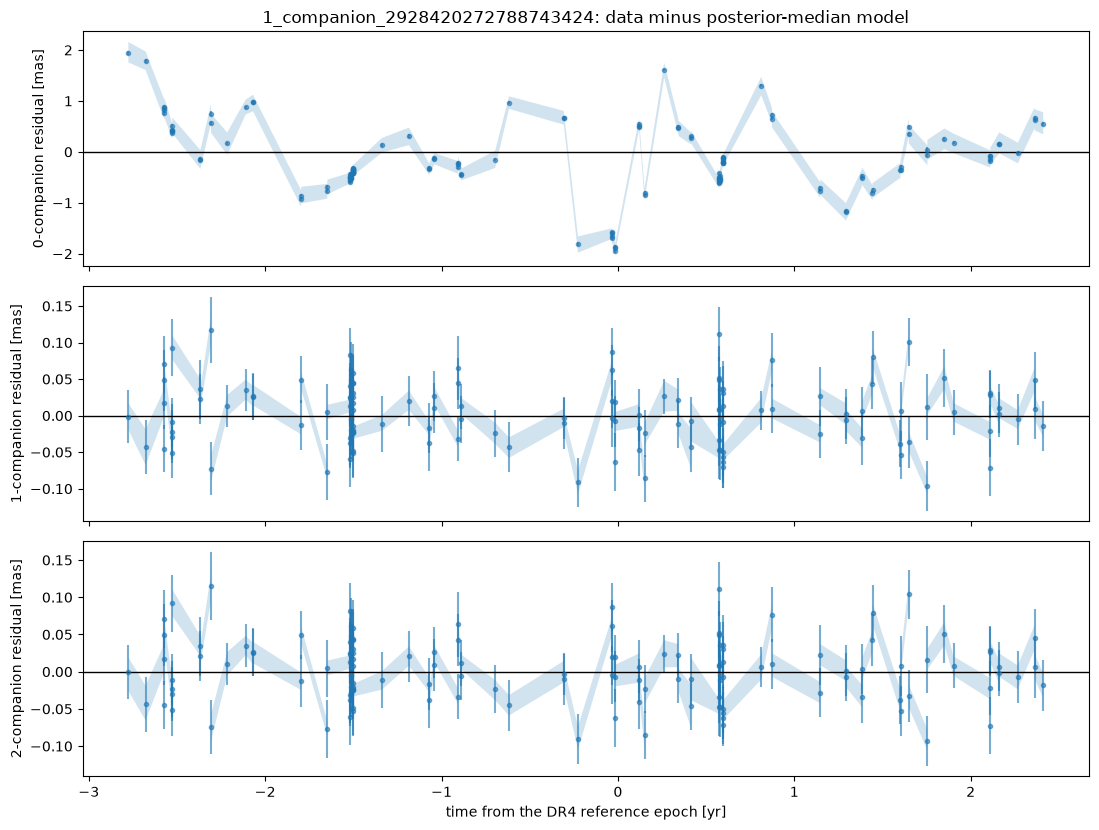

,companion,parameter,injected,median,-1sigma,+1sigma,pull
0,1,P [yr],2.9711,2.9683,0.0032,0.0029,-0.9234
1,1,Mp [Mjup],7.7268,7.6637,0.1094,0.1288,-0.5297
2,1,e,0.7112,0.7037,0.0105,0.0111,-0.6925


In [11]:
comparison_1 = compare_models(system_1)
display(recovery_table(system_1))

The zero-companion model is ruled out by a $\Delta$WAIC in the hundreds, and its fitted jitter of 0.7 mas is just the orbit being absorbed as noise. Between one and two companions WAIC sees a difference of about four, which is a tie, and a tie goes to the simpler model; the divergences column settles any doubt. The recovery table shows the period, mass and eccentricity all within a standard deviation of the injected values, and the fitted jitter of 0.025 mas is the expected gap between `sigma_reported` and `sigma_UEVA`. None of this used the injected orbit: the periodogram found the period, kepmodel found the rest, and NUTS mapped the posterior around it.

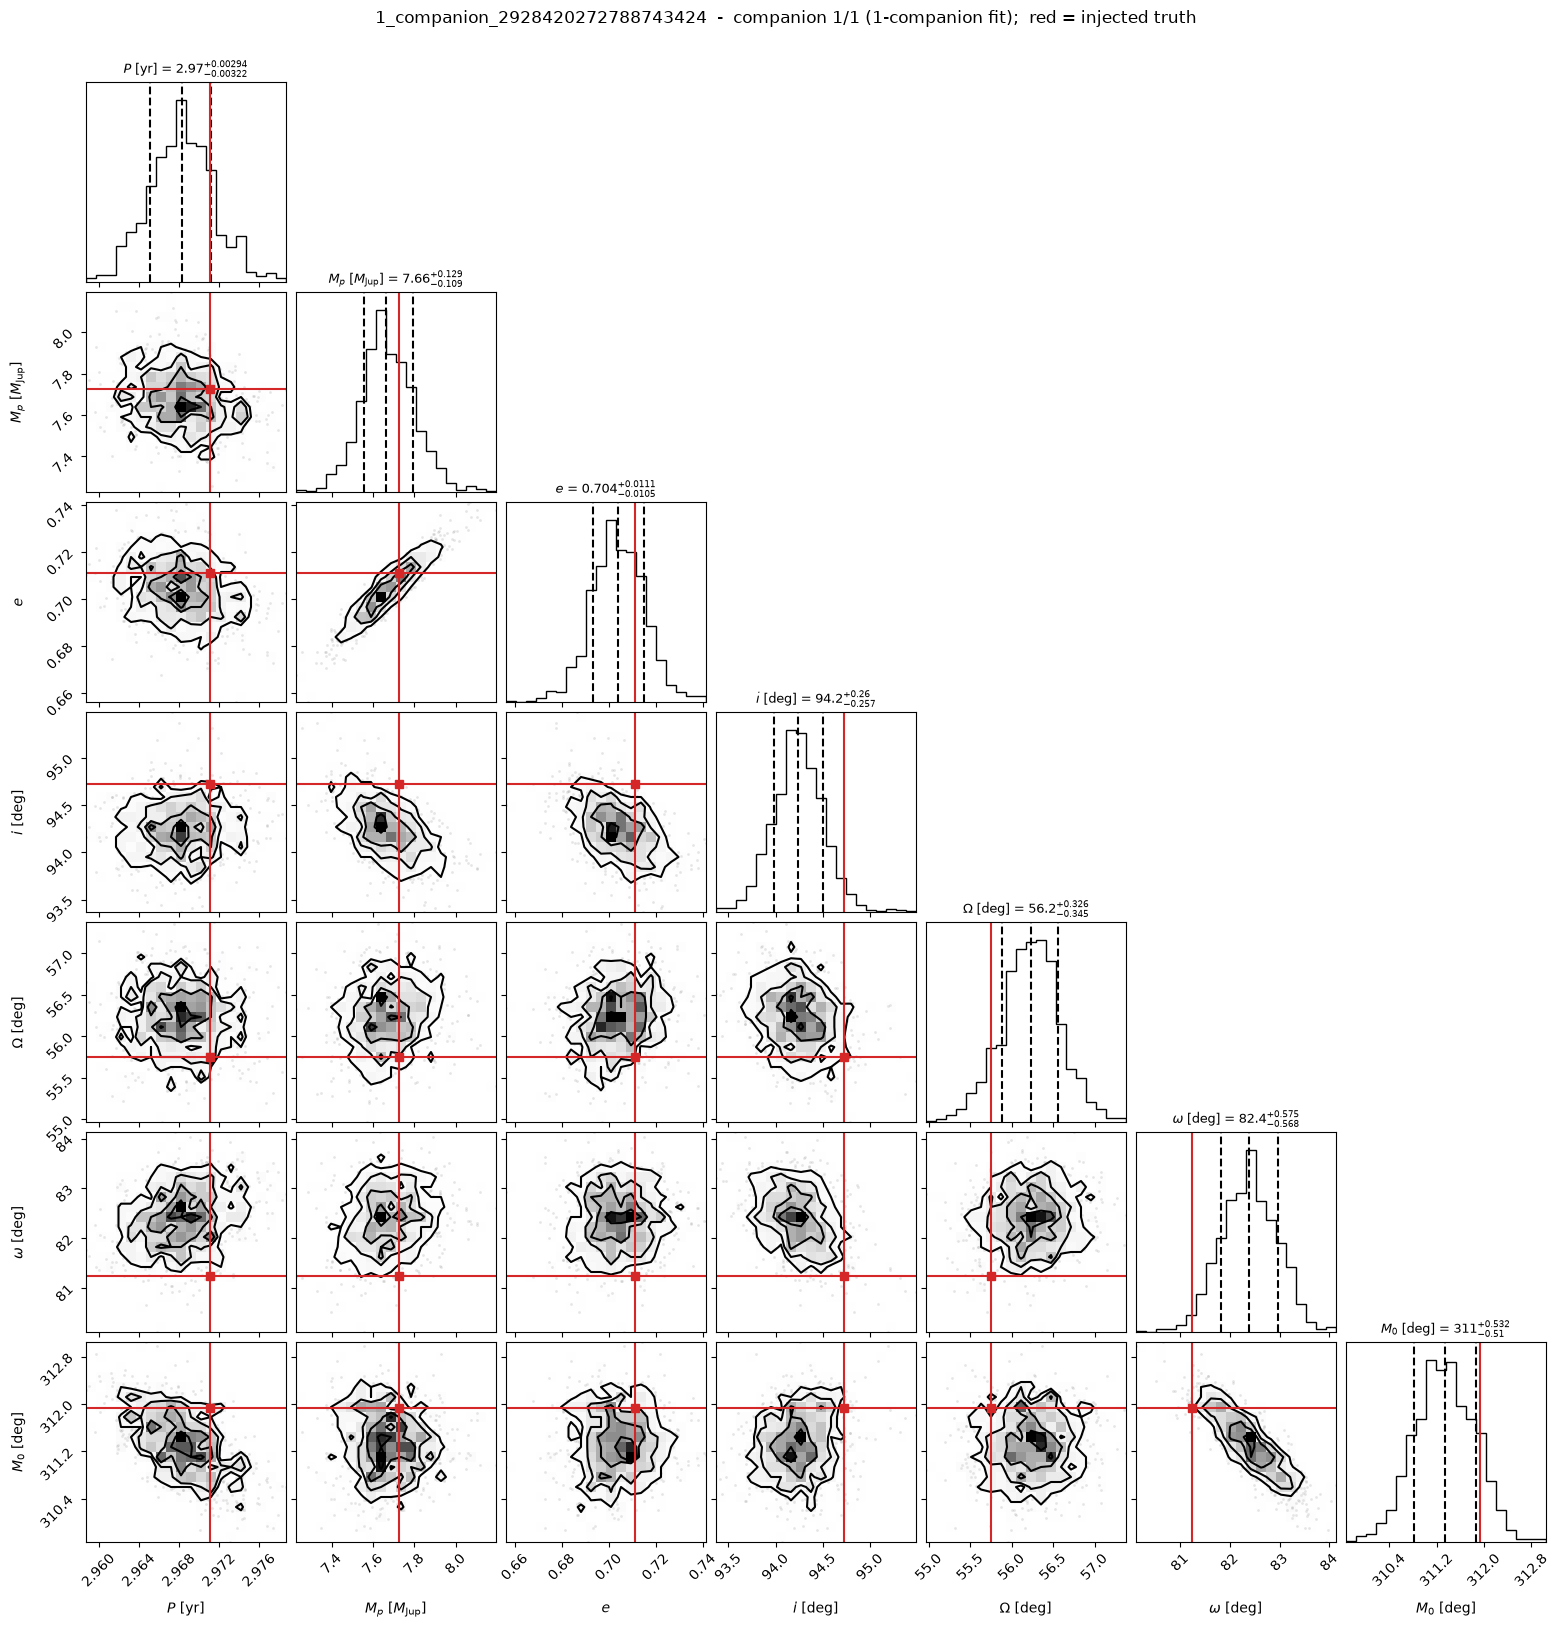

In [12]:
corner_plots(system_1)

The corner plot shows the same for all seven orbital elements, with everything within about two standard deviations of the injected values. Astrometry measures the full orbit, so unlike radial velocities there is no $M_p \sin i$ degeneracy and the mass itself is constrained, here to about 2%.

## 6. Example 2: two companions

The second example is the two-companion system whose *weaker* companion has the highest SNR, after the same cuts. This is a harder problem: two orbits with different periods and amplitudes have to be separated from each other and from the proper motion and parallax, with only 81 epochs to do it, and the search has to find both periods without being told either.

injected_solutions_2_companion_high_snr.parquet: 688 of 25,946 systems have all companions < 13 Mjup and all periods < 5.5 yr; top 8 by weakest-companion SNR_tot:


,system_id,n_epochs,mass_st_msun,parallax_mas,snr_weakest,klass,best_period,detected_cal,period_1,mass_pl_1,ecc_1,period_2,mass_pl_2,ecc_2
0,2_companion_3662657851291101824,81,0.781,36.645,50.755,unimodal,2.479,True,0.517,10.893,0.056,2.492,7.800,0.338
1,2_companion_4806949392212750848,92,0.223,20.217,45.592,broad,6.503,True,0.508,9.136,0.327,4.892,5.472,0.426
2,2_companion_1465638524401595392,74,0.318,34.513,44.272,unimodal,3.934,True,0.437,9.319,0.315,3.843,2.309,0.115
3,2_companion_1176209886733406592,65,0.789,61.279,40.221,unimodal,2.973,True,0.406,6.544,0.154,3.163,4.652,0.644
4,2_companion_4621712469256425728,78,0.220,21.061,35.583,unimodal,3.995,True,0.361,9.261,0.131,4.035,5.308,0.259
5,2_companion_6469849506753235328,111,0.503,8.962,35.500,broad,5.971,True,1.178,10.791,0.290,4.678,10.424,0.050
6,2_companion_1546590926993665664,194,0.270,22.038,34.704,unimodal,0.825,True,0.102,11.177,0.885,0.820,9.603,0.223
7,2_companion_3775245952190395008,87,0.204,27.020,34.353,unimodal,5.582,True,0.298,6.279,0.983,5.293,8.359,0.067



2_companion_3662657851291101824: 81 epochs over 5.39 yr; M* = 0.781 Msun, parallax = 36.65 mas, median reported sigma = 0.0370 mas
catalog periodogram verdict: klass = unimodal, best period = 2.479 yr, detected_cal = True, period_reliable_cal = True

injected companions (inner first; for the plots only):


,P [yr],Mp [Mjup],e,i [deg],Omega [deg],omega [deg],M0 [deg],alpha [mas],SNR_tot
1,0.517,10.893,0.056,31.28,162.472,49.783,159.654,0.287,50.755
2,2.492,7.800,0.338,31.28,162.472,237.751,294.594,0.587,86.838


,parameter,WLS,WLS_sigma,prior_scale,injected
0,alpha0_mas,0.126334,0.007848,10.0,0.000000
1,delta0_mas,0.270702,0.006716,10.0,0.000000
2,pmra_mas_yr,-236.676016,0.005228,10.0,-236.742914
3,pmdec_mas_yr,16.421647,0.004656,10.0,16.556039
4,parallax_mas,36.491763,0.009567,5.0,36.645227


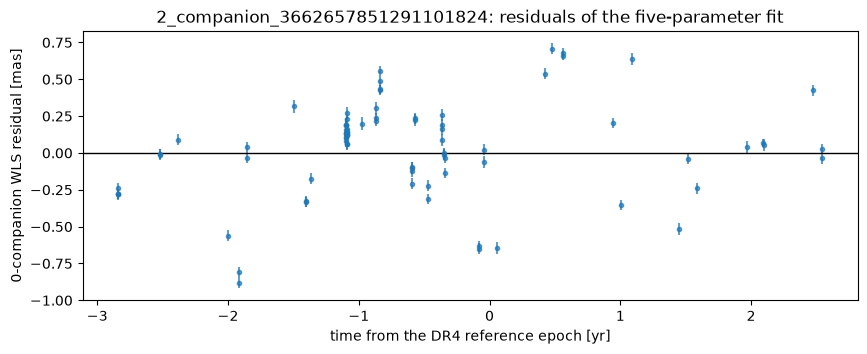

In [13]:
cfg = EXAMPLES["two companions"]
truth_2 = select_system(cfg["n_companions"], cfg["high_snr"], cfg["snr_rank"])
system_2 = load_system(truth_2)
system_2 = five_parameter_solution(system_2)

This is a 0.78 solar-mass star at 27 pc with a 10.9 Jupiter-mass planet at 0.52 yr and a 7.8 Jupiter-mass planet at 2.49 yr. The inner planet is closer in and so has the smaller reflex signature (0.29 mas against 0.59 mas) and the lower SNR, about 50. The two orbits are coplanar, as this pair was drawn. The catalog's periodogram found the outer planet at 2.48 yr; it says nothing about the inner one, which is exactly why we fit orbits rather than just finding periods. The least-squares residuals are again much larger than the error bars, but less obviously periodic than in Example 1.

companion 1: periodogram peak at P = 2.4790 yr (delta chi2 = 5577.9); after the kepmodel fit chi2 = 818.7, our model at the converted orbits: 818.7


companion 2: periodogram peak at P = 0.5166 yr (delta chi2 = 529.2); after the kepmodel fit chi2 = 124.2, our model at the converted orbits: 124.2


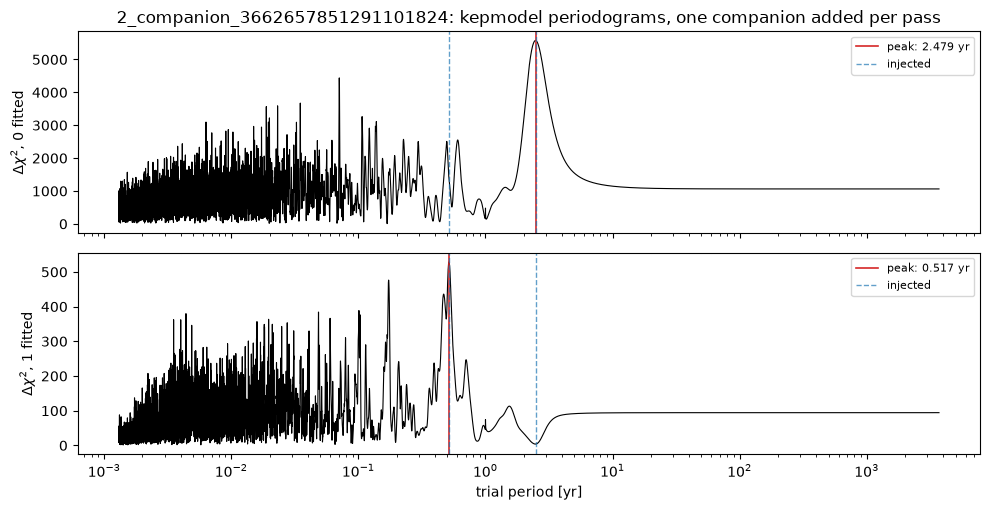

starting orbits for the highest-order model (converted from the kepmodel fit):


,P [yr],Mp [Mjup],e,i [deg],Omega [deg],omega [deg],M0 [deg]
1,0.525,14.793,0.438,44.741,131.335,78.361,157.653
2,2.472,7.604,0.331,27.436,172.658,232.392,292.550


In [14]:
starts_2 = periodogram_search(system_2)

The first periodogram picks out the outer planet at 2.48 yr with a $\Delta\chi^2$ of 5,600, but the panel also shows a cluster of peaks between 0.4 and 0.6 yr that a single companion cannot explain. Once the outer orbit is fitted and removed, the second pass is unambiguous: 0.517 yr with a $\Delta\chi^2$ of 530, against the injected 0.5175, and nothing else in the residuals comes close. The two starting orbits are within a few percent of the truth in period and mass. The inner one's eccentricity start (0.44 against 0.06 injected) is poor, which is a preview of what the posterior will say: with a signal this small, the shape of the orbit is the hardest thing to pin down.

In [15]:
fits_2 = run_fits(system_2)


0-companion model for 2_companion_3662657851291101824


(2 s incl. compilation)

                         mean       std    median      5.0%     95.0%     n_eff     r_hat
         alpha0_mas      0.16      0.07      0.16      0.04      0.27    673.26      1.00
         delta0_mas      0.26      0.06      0.25      0.17      0.36    559.45      1.00
  log_al_jitter_mas     -1.09      0.08     -1.09     -1.21     -0.94    619.83      1.00
       parallax_mas     36.50      0.09     36.50     36.37     36.65   1142.77      1.00
       pmdec_mas_yr     16.42      0.04     16.42     16.36     16.50    673.39      1.00
        pmra_mas_yr   -236.67      0.05   -236.67   -236.75   -236.59   1042.96      1.00


1-companion model for 2_companion_3662657851291101824


(8 s incl. compilation)

                         mean       std    median      5.0%     95.0%     n_eff     r_hat
               M0_1      4.97      0.16      4.98      4.69      5.22    363.51      1.00
            Omega_1      2.62      0.57      2.73      2.45      3.06    172.57      1.00
         alpha0_mas     -0.25      0.10     -0.25     -0.41     -0.10    244.33      1.00
            cos_i_1      0.69      0.11      0.68      0.52      0.89    158.54      1.00
         delta0_mas     -0.21      0.13     -0.20     -0.42     -0.01    284.02      1.00
     eccentricity_1      0.59      0.12      0.59      0.40      0.79    202.36      1.00
                h_1     -0.00      0.32      0.00     -0.46      0.48      1.21      2.15
                k_1      0.01      0.70     -0.02     -0.83      0.83      1.02      6.09
  log_al_jitter_mas     -2.10      0.09     -2.10     -2.27     -1.97    538.91      1.00
         log_mass_1      2.27      0.16      2.25      2.01      2.51    17

(35 s incl. compilation)

                         mean       std    median      5.0%     95.0%     n_eff     r_hat
               M0_1      2.98      0.54      2.99      2.07      3.79    103.28      1.00
               M0_2      5.08      0.16      5.10      4.83      5.35    404.24      1.00
            Omega_1      2.25      0.43      2.33      1.66      2.83    194.01      1.01
            Omega_2      2.41      0.95      2.78      0.21      3.14    214.29      1.01
         alpha0_mas      0.02      0.07      0.01     -0.10      0.14    230.68      1.00
            cos_i_1      0.79      0.10      0.79      0.62      0.95    190.77      1.01
            cos_i_2      0.90      0.05      0.90      0.83      0.98    212.71      1.02
         delta0_mas      0.14      0.11      0.13     -0.05      0.30    226.97      1.00
     eccentricity_1      0.34      0.16      0.33      0.07      0.57    172.62      1.01
     eccentricity_2      0.33      0.05      0.32      0.25      0.42    1

The pattern is the reverse of Example 1. Now the one-companion fit is the one in trouble: it has to explain two orbits with one, the two chains settle on different compromises, and $\hat R$ for the eccentricity parameters of that one orbit goes to 6. The two-companion fit is usable but not pristine: a handful of divergences, and the inner planet's $(h, k)$ have $\hat R$ around 1.5 with effective sample sizes in the single digits, because the eccentricity and argument of pericentre of a weak, nearly circular orbit are poorly determined and the chains explore that region slowly. For a tutorial that is acceptable. For a result you would run several times longer and look at the traces of those parameters.

2_companion_3662657851291101824: 2 companion(s) injected


,n_companions,WAIC,p_WAIC,divergences,jitter_mas (median),delta_WAIC
0,2,-224.815937,17.701361,17,0.036177,0.000000
1,1,-89.265634,12.424037,2,0.122742,135.550303
2,0,60.516850,6.544765,0,0.334987,285.332787


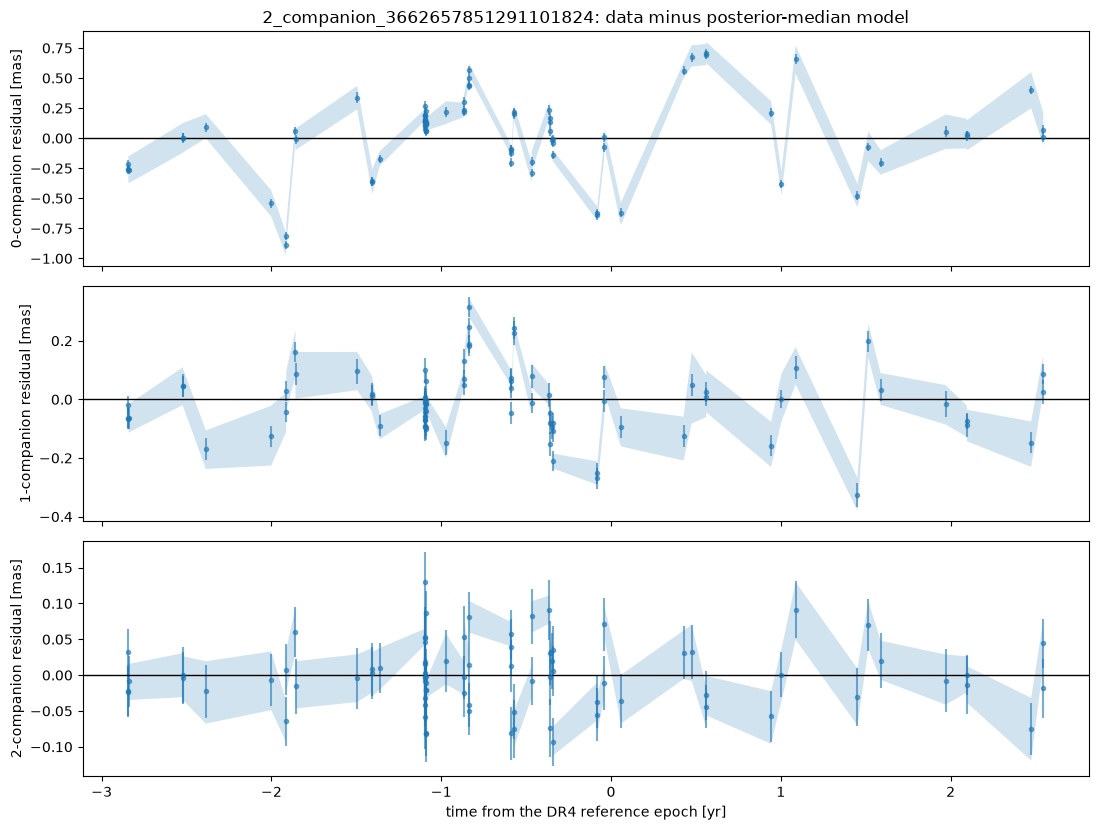

,companion,parameter,injected,median,-1sigma,+1sigma,pull
0,1,P [yr],0.5175,0.5221,0.0026,0.0025,1.8116
1,1,Mp [Mjup],10.8930,12.7657,1.4412,1.9971,1.0893
2,1,e,0.0559,0.3303,0.1574,0.1590,1.7343
3,2,P [yr],2.4922,2.4737,0.0137,0.0160,-1.2451
4,2,Mp [Mjup],7.8003,7.5297,0.3228,0.3636,-0.7884
5,2,e,0.3382,0.3243,0.0479,0.0544,-0.2720


In [16]:
comparison_2 = compare_models(system_2)
display(recovery_table(system_2))

The two-companion model wins by a $\Delta$WAIC of about 135 over the one-companion model, which in turn beats the zero-companion model by about 150: each planet is a clear detection on its own. The residual panels show it too. Only the two-companion residuals are flat at the level of the error bars, and its fitted jitter of 0.036 mas is back at the expected value, where the one-companion fit needs 0.12 mas of jitter to hide the inner planet.

Both planets are recovered. The outer one comes out within about a standard deviation in period, mass and eccentricity. The inner one is within about two, with a broad mass posterior (12.8 with errors of 1.4 to 2 Jupiter masses, against 10.9 injected) and an eccentricity that is poorly constrained (0.33 ± 0.16 against 0.06). At an SNR of 50, with a half-year orbit covered by 81 epochs spread over ten cycles, the eccentricity is the kind of parameter that goes first.

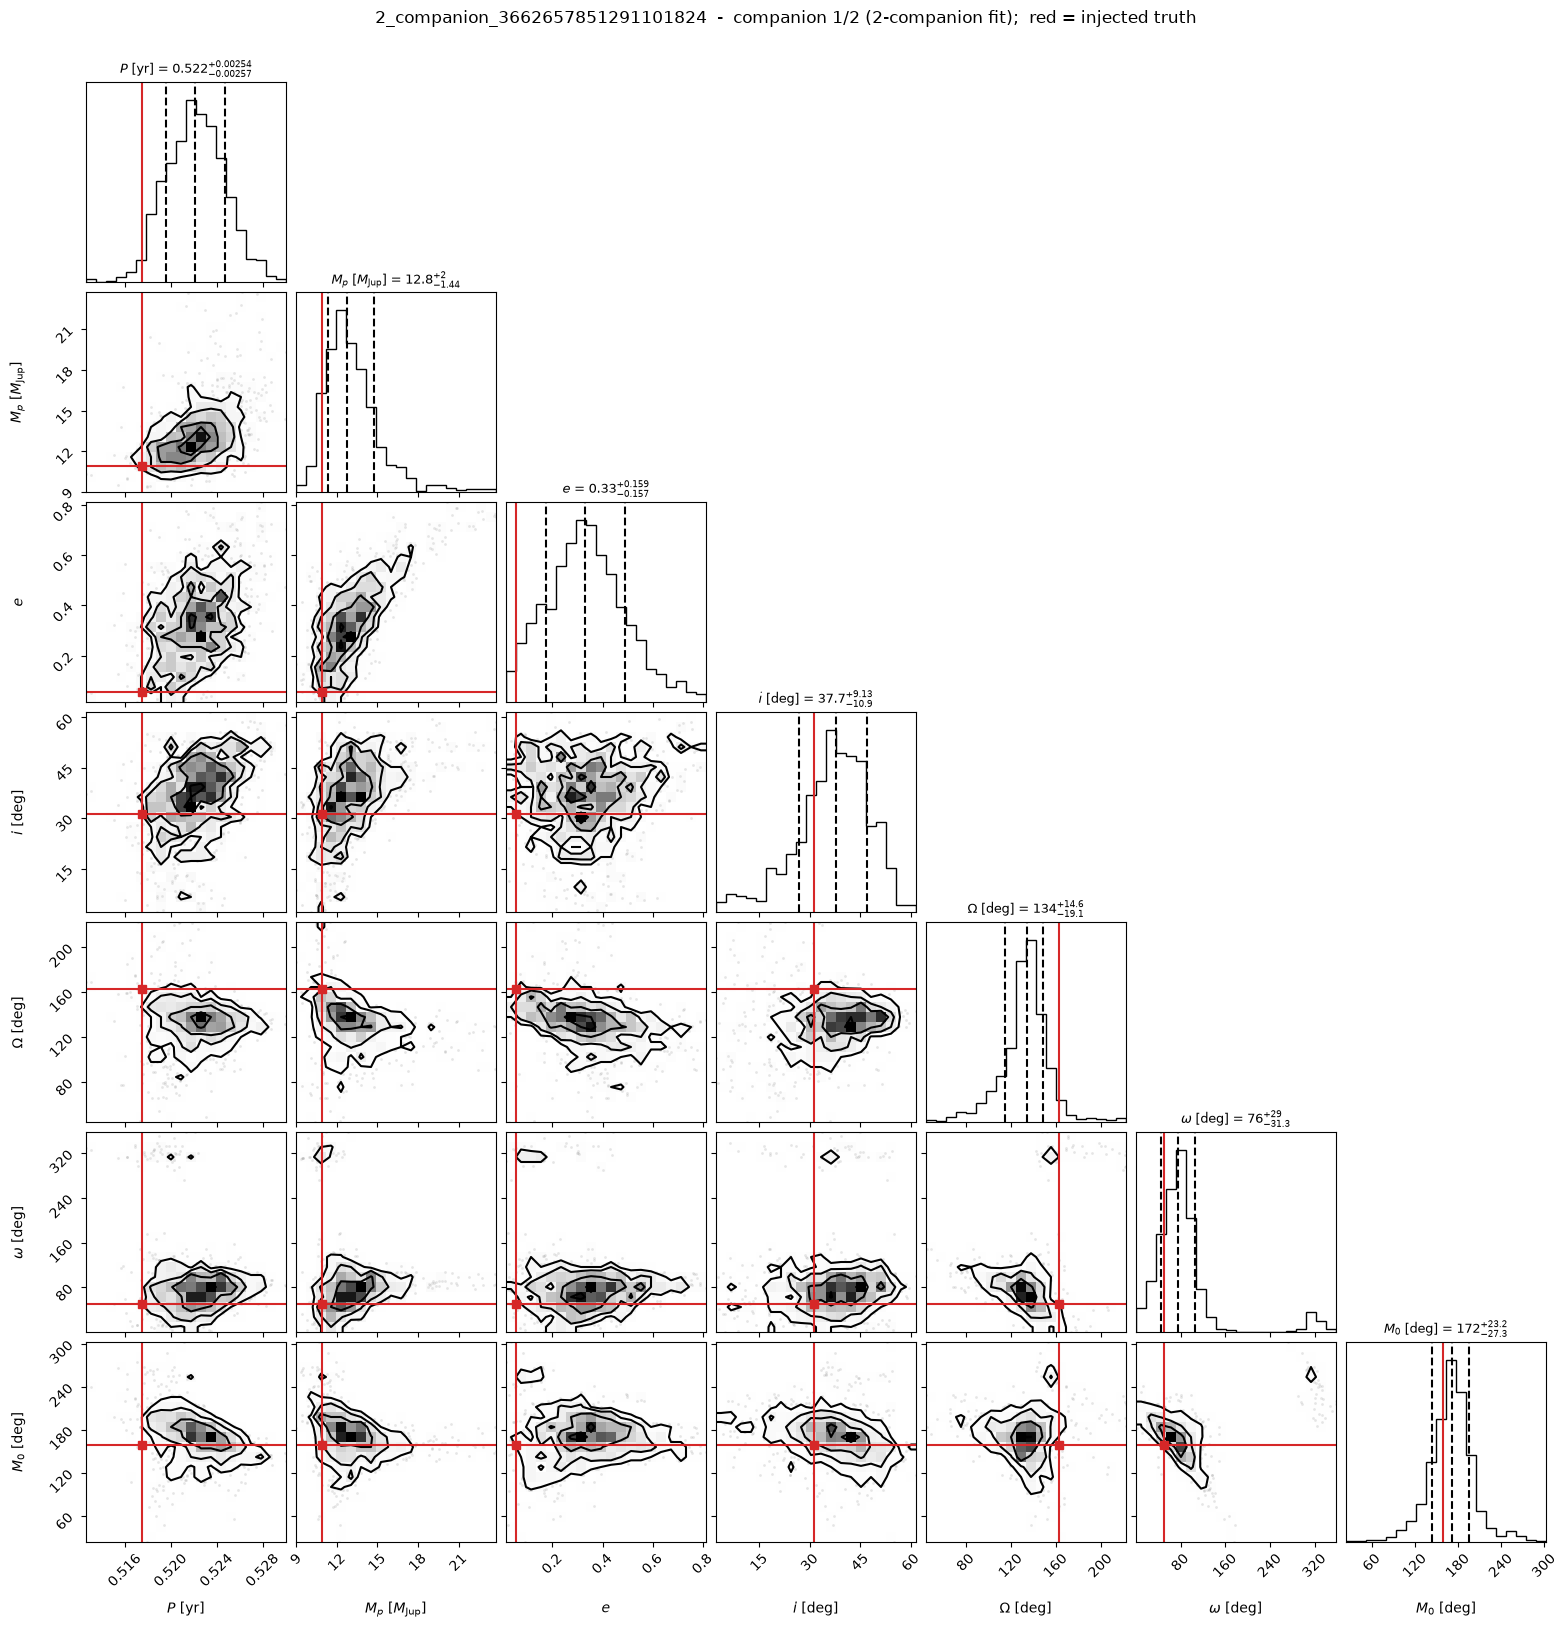

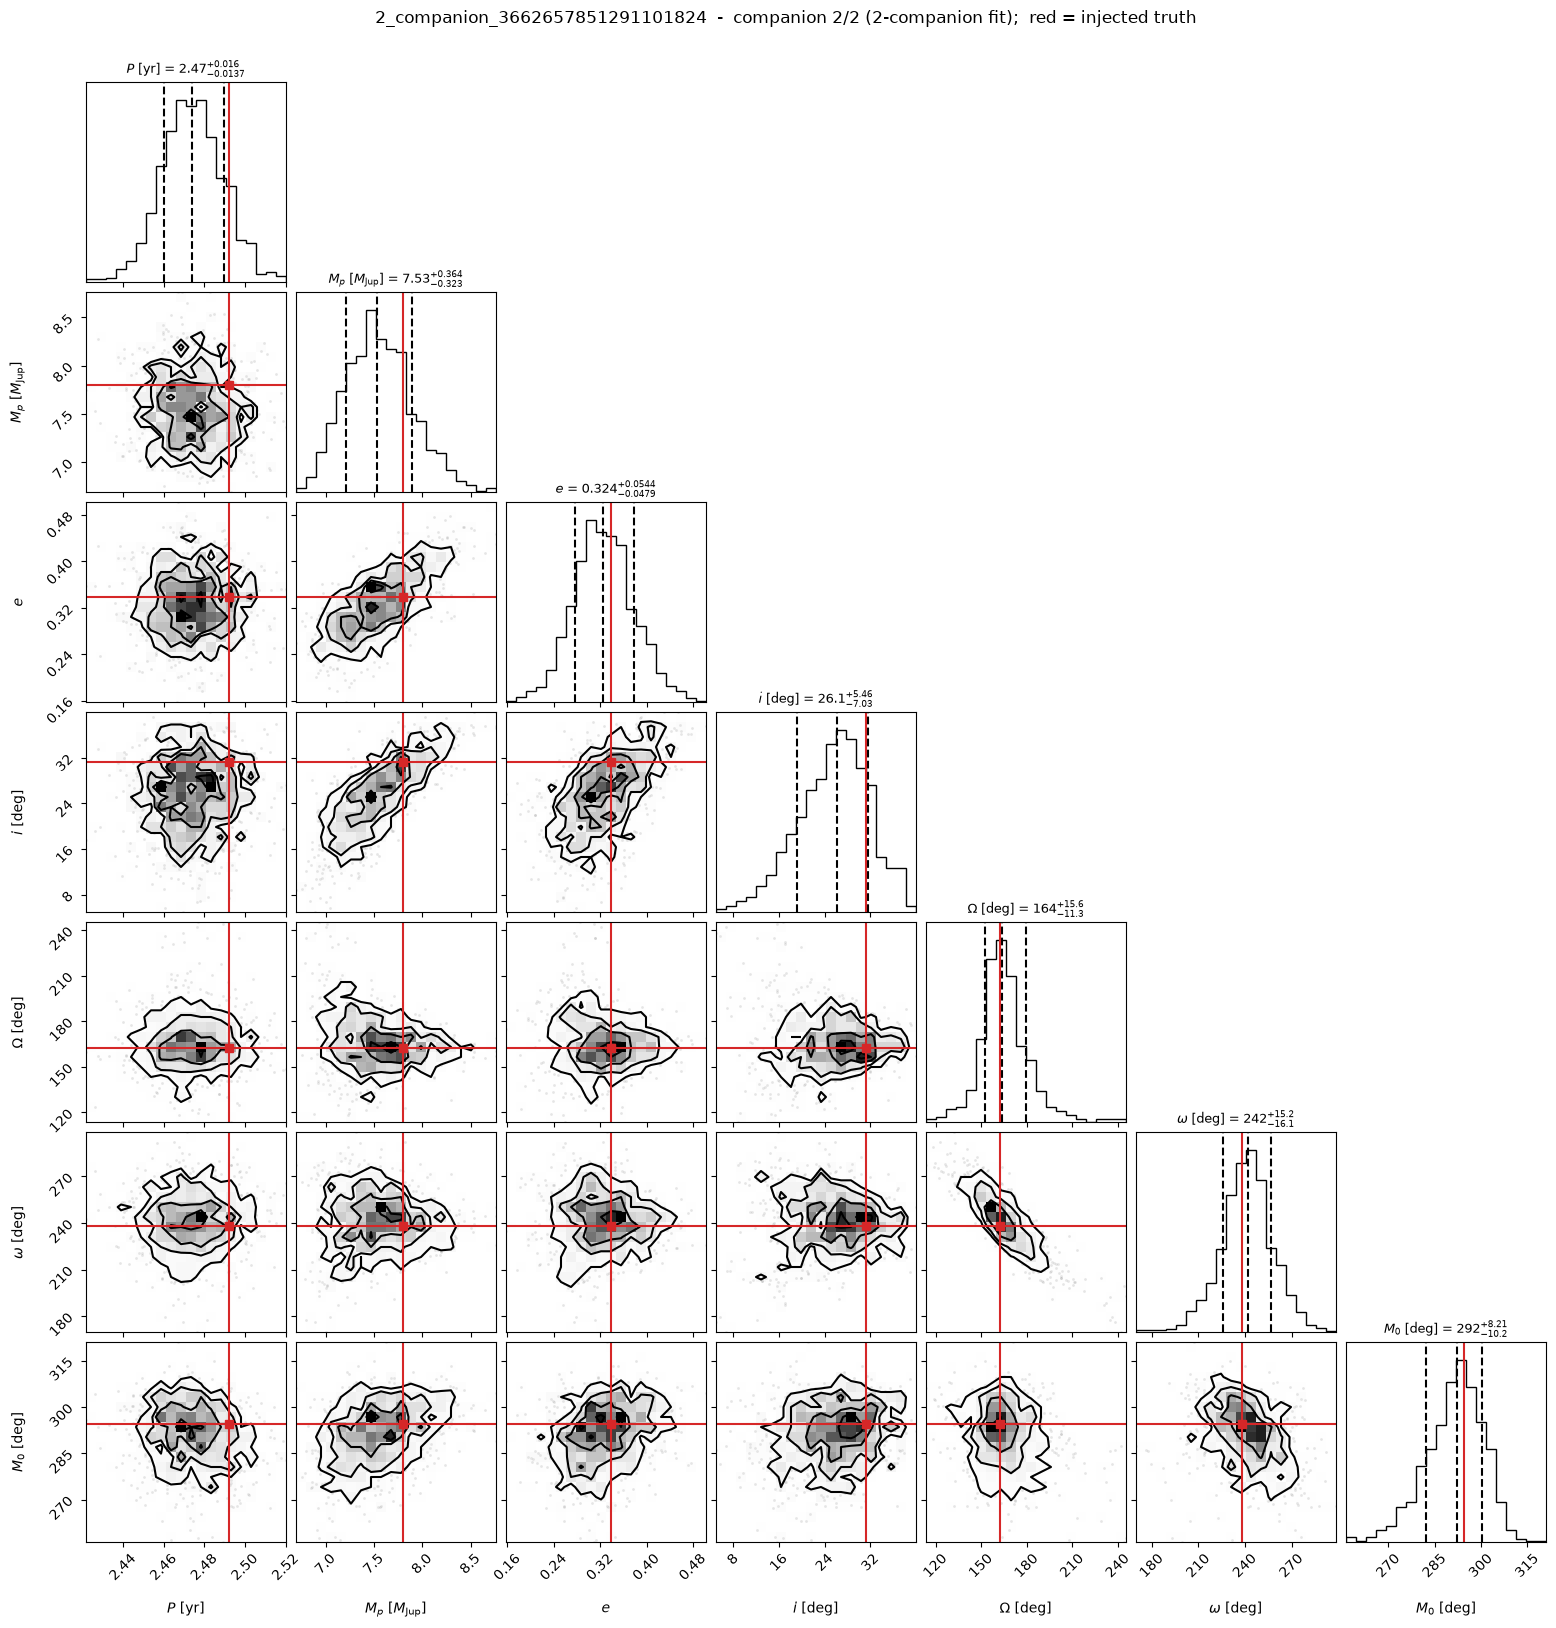

In [17]:
corner_plots(system_2)

The corner plots say the same thing per element. The outer planet's posteriors sit on the red lines, $\Omega$ and $\omega$ included, with the search having found the orbit on its own. The inner planet's are wider and pulled along a correlated direction toward higher mass and higher eccentricity (the two are degenerate when the orbit is barely resolved), and its $\omega$ has a small secondary mode: for an orbit that is nearly circular the argument of pericentre is barely defined. The $(h, k)$ parameterization handles that gracefully inside the sampler, but a corner plot in $\omega$ does not.

## Where to go from here

A few things to keep in mind when you run this on other systems.

- Before interpreting a fit, look at the chains: $\hat R$ near one, effective sample sizes that are not single digits, and few or no divergences. The model with one companion more than the data support will sample badly, and that is information, not a bug.
- The periodogram start is only as good as the periodogram. For a companion whose period is longer than the baseline, or whose signal is below the noise, the peak will be wrong or absent, and NUTS will faithfully explore the wrong mode. Look at the periodogram panels before trusting a fit, and try the next-highest peak if the first one does not converge.
- A $\Delta$WAIC of a few is a tie, and the simpler model wins a tie. A $\Delta$WAIC in the tens or hundreds is a detection.
- The jitter should come out near the difference between `sigma_UEVA` and `sigma_reported`, a few hundredths of a mas. If it comes out much larger, the model is missing something, as the zero-companion fits above show.
- Orbits longer than the baseline are degenerate with proper motion and acceleration. The cuts in `select_system` avoid them on purpose; remove the cut if you want to see what that looks like.
- Any other system: `select_system(n_companions, high_snr, snr_rank)` walks down the ranking, `select_system(n_companions, high_snr, gaia_source_id=...)` picks a specific star, and then `load_system`, `five_parameter_solution`, `periodogram_search`, `run_fits`, `compare_models` and `corner_plots` work as above. The companion-free control population (`0_companion`) has no injected orbit, so skip the corner plots there.